<a href="https://colab.research.google.com/github/aleakucing/Pembelajaran-Memsin/blob/main/JS07/JS07_Assigment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
df = pd.read_csv('/content/drive/MyDrive/PemMes/JS7/CC_Customer_Dataset.csv')

print(df.head())

print(df.info())

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    i

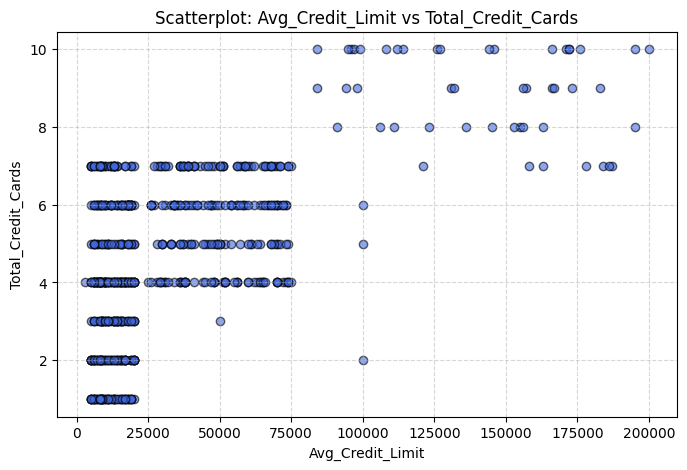

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    color='royalblue',
    alpha=0.6,
    edgecolors='k'
)
plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [4]:
# Memilih fitur-fitur analisis nasabah
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]
X = df[features]

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dimensi fitur siap latih:", X_scaled.shape)

Dimensi fitur siap latih: (660, 5)


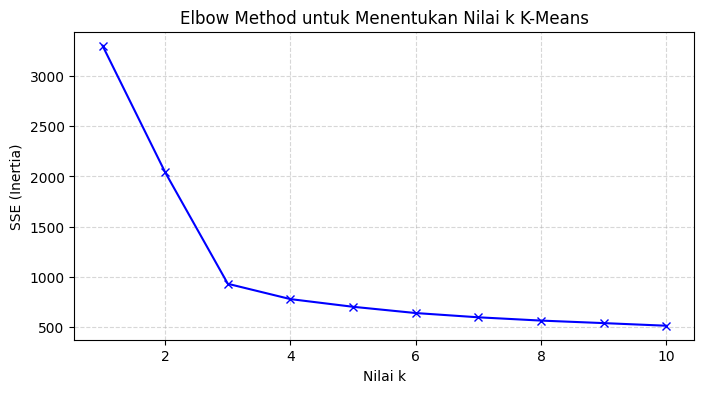

In [5]:
sse = []
K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    sse.append(km.inertia_)

# Visualisasi kurva elbow
plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('Nilai k')
plt.ylabel('SSE (Inertia)')
plt.title('Elbow Method untuk Menentukan Nilai k K-Means')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

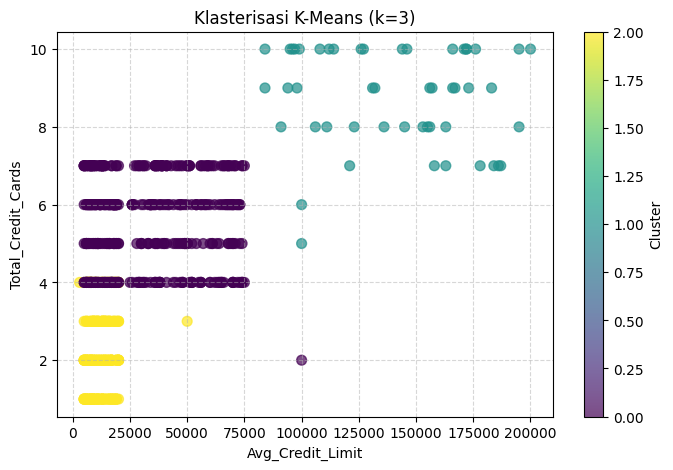

In [6]:
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans_opt.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['Cluster_KMeans'],
    cmap='viridis',
    s=50,
    alpha=0.7
)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Klasterisasi K-Means (k=3)')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

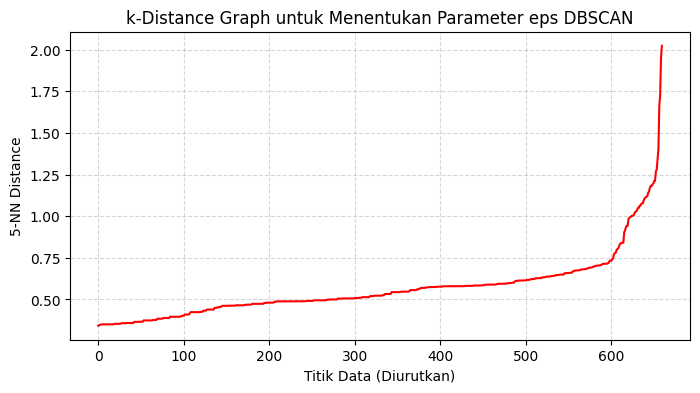

In [8]:
nbrs = NearestNeighbors(n_neighbors=5).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances, 'r-')
plt.xlabel('Titik Data (Diurutkan)')
plt.ylabel('5-NN Distance')
plt.title('k-Distance Graph untuk Menentukan Parameter eps DBSCAN')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [9]:
# Pelatihan model DBSCAN
dbscan = DBSCAN(eps=0.9, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

# Menghitung metrik evaluasi untuk keseluruhan data
sil_all = silhouette_score(X_scaled, df['Cluster_DBSCAN'])
dbi_all = davies_bouldin_score(X_scaled, df['Cluster_DBSCAN'])

# Menghitung metrik evaluasi tanpa titik noise (-1)
mask_clean = df['Cluster_DBSCAN'] != -1
sil_clean = silhouette_score(X_scaled[mask_clean], df['Cluster_DBSCAN'][mask_clean])
dbi_clean = davies_bouldin_score(X_scaled[mask_clean], df['Cluster_DBSCAN'][mask_clean])

jumlah_cluster = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'].values else 0)
jumlah_noise = (df['Cluster_DBSCAN'] == -1).sum()

print(f"Jumlah klaster terbentuk : {jumlah_cluster}")
print(f"Jumlah data noise       : {jumlah_noise}")
print("--- Evaluasi Seluruh Data ---")
print(f"Silhouette Score        : {sil_all:.4f}")
print(f"Davies-Bouldin Index    : {dbi_all:.4f}")
print("--- Evaluasi Tanpa Noise ---")
print(f"Silhouette Score        : {sil_clean:.4f}")
print(f"Davies-Bouldin Index    : {dbi_clean:.4f}")

Jumlah klaster terbentuk : 3
Jumlah data noise       : 27
--- Evaluasi Seluruh Data ---
Silhouette Score        : 0.4645
Davies-Bouldin Index    : 1.9420
--- Evaluasi Tanpa Noise ---
Silhouette Score        : 0.4940
Davies-Bouldin Index    : 0.8784
